# 🎬 Netflix Movie Data Analysis Project

**Objective:** Is project mein hum 9,000+ movies ke dataset ko analyze karenge aur Netflix ke liye important business questions ke answers dhundhenge.

---

### 📋 Questions jo hume answer karne hain:
1. What is the most frequent genre of movies released on Netflix?
2. Which has highest votes in vote avg column?
3. What movie got the highest popularity? What's its genre?
4. What movie got the lowest popularity? What's its genre?
5. Which year has the most filmed movies?

---
## 📦 Step 1: Libraries Import Karna

Sabse pehle hum kaam ki libraries import karte hain:
- **pandas** → data load karne aur clean karne ke liye
- **matplotlib** → graphs/charts banane ke liye
- **seaborn** → sundar aur colorful visualizations ke liye
- **warnings** → unnecessary warning messages band karne ke liye

In [1]:
import numpy as np

In [2]:
import matplotlib.pyplot as plt

In [3]:
import pandas as pd

In [4]:
import seaborn as sns

In [32]:
import warnings

warnings.filterwarnings('ignore')

In [33]:
#   ----------- CSV file loading -------------------

In [7]:
df = pd.read_csv('mymoviedb.csv', on_bad_lines='skip', engine='python')

print(f'✅ Dataset load ho gaya!')
print(f'📊 Total Rows    : {df.shape[0]}')
print(f'📊 Total Columns : {df.shape[1]}')

✅ Dataset load ho gaya!
📊 Total Rows    : 9837
📊 Total Columns : 9


In [8]:
# Pehli 5 rows dekho
print('📌 Dataset ki pehli 5 rows:')
df.head()

📌 Dataset ki pehli 5 rows:


,Release_Date,Title,Overview,Popularity,Vote_Count,Vote_Average,Original_Language,Genre,Poster_Url
0,2021-12-15,Spider-Man: No Way Home,Peter Parker is unmasked and no longer able to...,5083.954,8940,8.3,en,"Action, Adventure, Science Fiction",https://image.tmdb.org/t/p/original/1g0dhYtq4i...
1,2022-03-01,The Batman,"In his second year of fighting crime, Batman u...",3827.658,1151,8.1,en,"Crime, Mystery, Thriller",https://image.tmdb.org/t/p/original/74xTEgt7R3...
2,2022-02-25,No Exit,Stranded at a rest stop in the mountains durin...,2618.087,122,6.3,en,Thriller,https://image.tmdb.org/t/p/original/vDHsLnOWKl...
3,2021-11-24,Encanto,"The tale of an extraordinary family, the Madri...",2402.201,5076,7.7,en,"Animation, Comedy, Family, Fantasy",https://image.tmdb.org/t/p/original/4j0PNHkMr5...
4,2021-12-22,The King's Man,As a collection of history's worst tyrants and...,1895.511,1793,7.0,en,"Action, Adventure, Thriller, War",https://image.tmdb.org/t/p/original/aq4Pwv5Xeu...


In [9]:
# Har column ka data type aur non-null count dekho
print('📌 Dataset Info:')
df.info()

📌 Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9837 entries, 0 to 9836
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Release_Date       9837 non-null   object 
 1   Title              9828 non-null   object 
 2   Overview           9828 non-null   object 
 3   Popularity         9827 non-null   float64
 4   Vote_Count         9827 non-null   object 
 5   Vote_Average       9827 non-null   object 
 6   Original_Language  9827 non-null   object 
 7   Genre              9826 non-null   object 
 8   Poster_Url         9826 non-null   object 
dtypes: float64(1), object(8)
memory usage: 691.8+ KB


In [10]:
# Numeric columns ki basic statistics
print('📌 Basic Statistics:')
df.describe()

📌 Basic Statistics:


,Popularity
count,9827.000000
mean,40.320570
std,108.874308
min,7.100000
25%,16.127500
50%,21.191000
75%,35.174500
max,5083.954000


In [ ]:
## 🧹 Step 4: Data Cleaning

1. Null (missing) values check karni hain
2. Galat data types fix karni hain
3. Duplicate rows hatani hain
4. Date column se year nikalna hai

In [16]:
# ---- 4.1: Null Values Check ----
print('📌 Har column mein kitni NULL values hain:')
print(df.isnull().sum())
print(f'Total null values: {df.isnull().sum().sum()}')

📌 Har column mein kitni NULL values hain:
Release_Date          0
Title                 9
Overview              9
Popularity           10
Vote_Count           10
Vote_Average         10
Original_Language    10
Genre                11
Poster_Url           11
dtype: int64
Total null values: 80


In [17]:
# ---- 4.2: Duplicate Rows Check ----
print(f'📌 Duplicate rows: {df.duplicated().sum()}')
# Duplicates nahi hain to kuch karne ki zaroorat nahi

📌 Duplicate rows: 0


In [18]:
# ---- 4.3: Data Types Fix Karna ----

# Vote_Average aur Vote_Count strings hain — inhe numbers banana chahiye
# pd.to_numeric() → text ko number mein badalta hai
# errors='coerce' → jo value number nahi bani use NaN (missing) kar do

df['Vote_Average'] = pd.to_numeric(df['Vote_Average'], errors='coerce')
df['Vote_Count']   = pd.to_numeric(df['Vote_Count'],   errors='coerce')
df['Popularity']   = pd.to_numeric(df['Popularity'],   errors='coerce')

print('✅ Vote_Average, Vote_Count aur Popularity numeric ho gaye!')
print()
print('Updated dtypes:')
print(df[['Vote_Average', 'Vote_Count', 'Popularity']].dtypes)

✅ Vote_Average, Vote_Count aur Popularity numeric ho gaye!

Updated dtypes:
Vote_Average    float64
Vote_Count      float64
Popularity      float64
dtype: object


In [19]:
# ---- 4.4: Release_Date se Year column banana ----

# Pehle string ko proper date format mein badlo
df['Release_Date'] = pd.to_datetime(df['Release_Date'], errors='coerce')

# Ab sirf year nikalo ek naye column mein
df['Year'] = df['Release_Date'].dt.year

print('✅ Release_Date datetime ban gaya aur Year column create ho gaya!')
print()
print('Year column sample:')
print(df['Year'].dropna().astype(int).value_counts().head(5))

✅ Release_Date datetime ban gaya aur Year column create ho gaya!

Year column sample:
Year
2021    714
2018    530
2017    510
2019    500
2016    470
Name: count, dtype: int64


In [20]:
# ---- 4.5: Null rows hatao un columns se jahan analysis karni hai ----

# Genre, Popularity, Vote_Average, Vote_Count ke nulls drop karo
df_clean = df.dropna(subset=['Genre', 'Popularity', 'Vote_Average', 'Vote_Count'])

print(f'✅ Cleaning ke baad rows : {len(df_clean)}')
print(f'   Cleaning se pehle rows: {len(df)}')
print(f'   Hatayi gayi rows      : {len(df) - len(df_clean)}')

✅ Cleaning ke baad rows : 9826
   Cleaning se pehle rows: 9837
   Hatayi gayi rows      : 11


In [21]:
# ---- 4.6: Clean data verify karo ----
print('📌 Clean data ki final null check:')
print(df_clean[['Genre', 'Popularity', 'Vote_Average', 'Vote_Count']].isnull().sum())
print()
print('✅ Data cleaning complete! Ab analysis karte hain.')

📌 Clean data ki final null check:
Genre           0
Popularity      0
Vote_Average    0
Vote_Count      0
dtype: int64

✅ Data cleaning complete! Ab analysis karte hain.


---
## ❓ Question 1: What is the most frequent genre of movies released on Netflix?

**Problem:** Genre column mein ek movie ke multiple genres hain jaise `'Action, Adventure, Science Fiction'`.

**Solution:** Pehle hum genres ko alag alag karenge (split), phir count karenge ki kaun sa genre sabse zyada baar aaya.

In [22]:
# Genre column mein ek cell mein multiple genres hain, comma se alag
# str.split(', ') → genre string ko list mein todta hai
# .explode()      → ek row ko multiple rows mein convert karta hai (ek genre = ek row)

all_genres = df_clean['Genre'].str.split(', ').explode()

# Ab har genre ko count karo
genre_counts = all_genres.value_counts()

print('📊 Top 10 Most Frequent Genres:')
print(genre_counts.head(10))
print()
print(f'🏆 ANSWER: Sabse frequent genre hai → "{genre_counts.index[0]}" ({genre_counts.iloc[0]} movies)')

📊 Top 10 Most Frequent Genres:
Genre
Drama        3744
Comedy       3031
Action       2686
Thriller     2488
Adventure    1853
Romance      1476
Horror       1470
Animation    1438
Family       1414
Fantasy      1308
Name: count, dtype: int64

🏆 ANSWER: Sabse frequent genre hai → "Drama" (3744 movies)


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17232\633359454.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


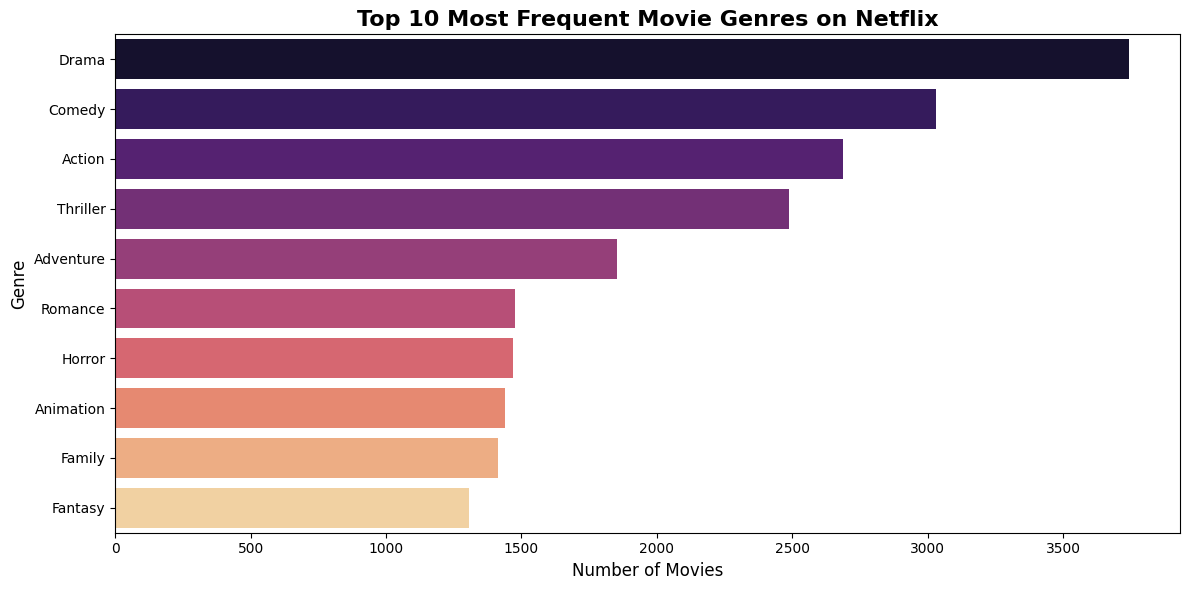

In [23]:
# Visualization: Top 10 genres ka bar chart
plt.figure(figsize=(12, 6))
sns.barplot(
    x=genre_counts.head(10).values,
    y=genre_counts.head(10).index,
    palette='magma'
)
plt.title('Top 10 Most Frequent Movie Genres on Netflix', fontsize=16, fontweight='bold')
plt.xlabel('Number of Movies', fontsize=12)
plt.ylabel('Genre', fontsize=12)
plt.tight_layout()
plt.show()

---
## ❓ Question 2: Which has highest votes in Vote Average column?

Yahan hum dekhenge ki kaun si movie ka Vote_Average (rating) sabse zyada hai.

In [24]:
# Vote_Average ke basis pe top 10 movies nikalo
top_voted = df_clean.nlargest(10, 'Vote_Average')[['Title', 'Vote_Average', 'Vote_Count', 'Genre']]

print('📊 Top 10 Highest Rated Movies (Vote Average):')
print(top_voted.to_string(index=False))
print()

best = df_clean.loc[df_clean['Vote_Average'].idxmax()]
print(f'🏆 ANSWER: Sabse zyada Vote Average hai → "{best["Title"]}" with rating {best["Vote_Average"]}')

📊 Top 10 Highest Rated Movies (Vote Average):
                                        Title  Vote_Average  Vote_Count                      Genre
                   Kung Fu Master Huo Yuanjia          10.0         1.0              Action, Drama
            Franco Escamilla: Por La Anécdota           9.2        92.0                     Comedy
Demon Slayer: Kimetsu no Yaiba Sibling's Bond           9.1        27.0 Action, Animation, Fantasy
                            Impossible Things           9.1        82.0              Family, Drama
        The Three Deaths of Marisela Escobedo           9.0       183.0         Documentary, Crime
                                Mission «Sky»           9.0        34.0                 Drama, War
                  Sex School: Dorms of Desire           9.0         1.0                     Comedy
                                  My Sex Doll           9.0         4.0            Comedy, Romance
                              Ni tuyo, Ni mía           8.9    

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17232\2421883646.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


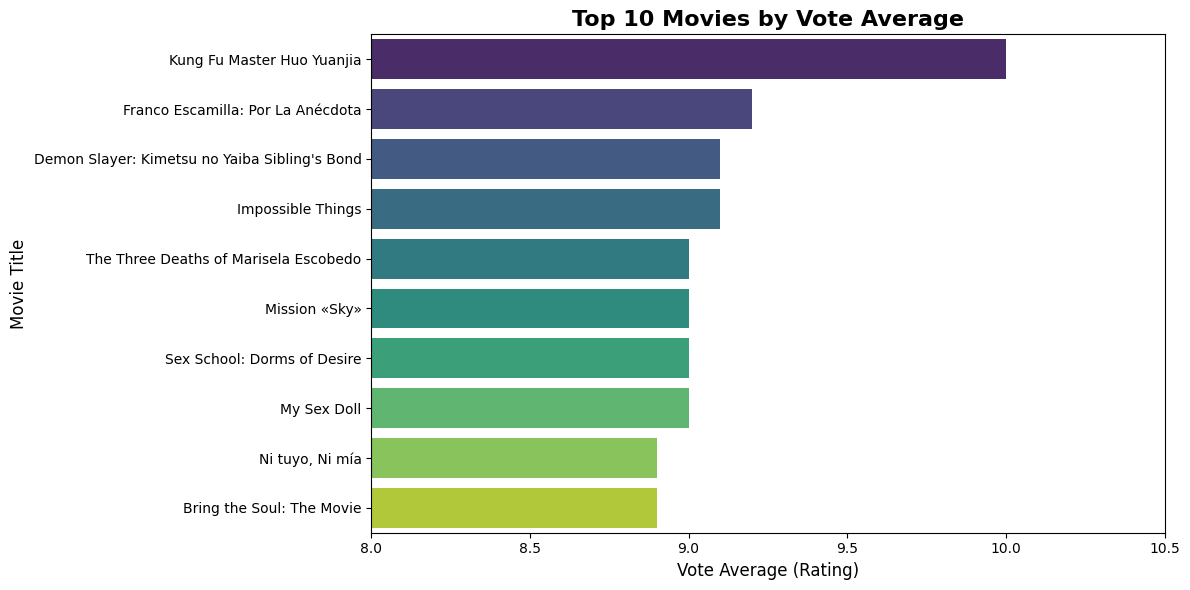

In [25]:
# Visualization: Top 10 highest rated movies
plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_voted,
    x='Vote_Average',
    y='Title',
    palette='viridis'
)
plt.title('Top 10 Movies by Vote Average', fontsize=16, fontweight='bold')
plt.xlabel('Vote Average (Rating)', fontsize=12)
plt.ylabel('Movie Title', fontsize=12)
plt.xlim(8, 10.5)
plt.tight_layout()
plt.show()

---
## ❓ Question 3: What movie got the highest popularity? What's its genre?

Popularity score sabse zyada jis movie ka hai, woh kaun si movie hai aur uska genre kya hai?

In [26]:
# Sabse zyada popularity wali movie dhundo
# idxmax() → maximum value ki row ka index deta hai
max_pop_idx = df_clean['Popularity'].idxmax()
most_popular = df_clean.loc[max_pop_idx]

print('🏆 ANSWER: Highest Popularity Movie:')
print(f'   Title      : {most_popular["Title"]}')
print(f'   Popularity : {most_popular["Popularity"]}')
print(f'   Genre      : {most_popular["Genre"]}')
print(f'   Rating     : {most_popular["Vote_Average"]}')

🏆 ANSWER: Highest Popularity Movie:
   Title      : Spider-Man: No Way Home
   Popularity : 5083.954
   Genre      : Action, Adventure, Science Fiction
   Rating     : 8.3


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17232\2450763205.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


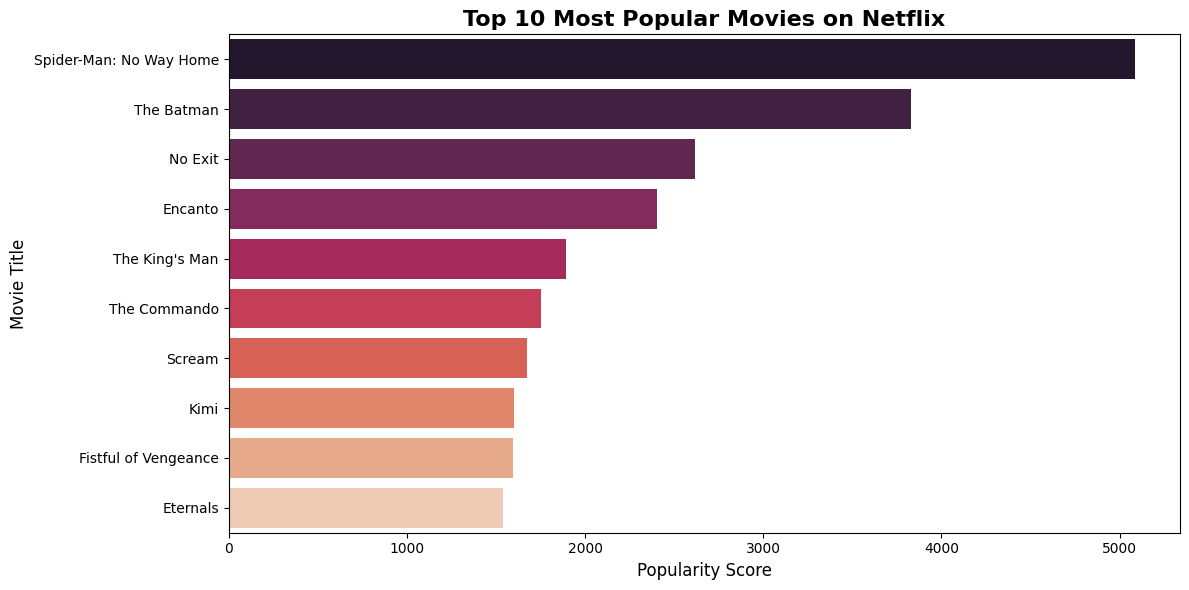

In [27]:
# Visualization: Top 10 most popular movies
top_popular = df_clean.nlargest(10, 'Popularity')[['Title', 'Popularity']]

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_popular,
    x='Popularity',
    y='Title',
    palette='rocket'
)
plt.title('Top 10 Most Popular Movies on Netflix', fontsize=16, fontweight='bold')
plt.xlabel('Popularity Score', fontsize=12)
plt.ylabel('Movie Title', fontsize=12)
plt.tight_layout()
plt.show()

---
## ❓ Question 4: What movie got the lowest popularity? What's its genre?

Ab dekhte hain sabse kam popular movie kaun si hai.

In [28]:
# Sabse kam popularity wali movie dhundo
# idxmin() → minimum value ki row ka index deta hai
min_pop_idx = df_clean['Popularity'].idxmin()
least_popular = df_clean.loc[min_pop_idx]

print('📉 ANSWER: Lowest Popularity Movie:')
print(f'   Title      : {least_popular["Title"]}')
print(f'   Popularity : {least_popular["Popularity"]}')
print(f'   Genre      : {least_popular["Genre"]}')
print(f'   Rating     : {least_popular["Vote_Average"]}')

📉 ANSWER: Lowest Popularity Movie:
   Title      : The United States vs. Billie Holiday
   Popularity : 13.354
   Genre      : Music, Drama, History
   Rating     : 6.7


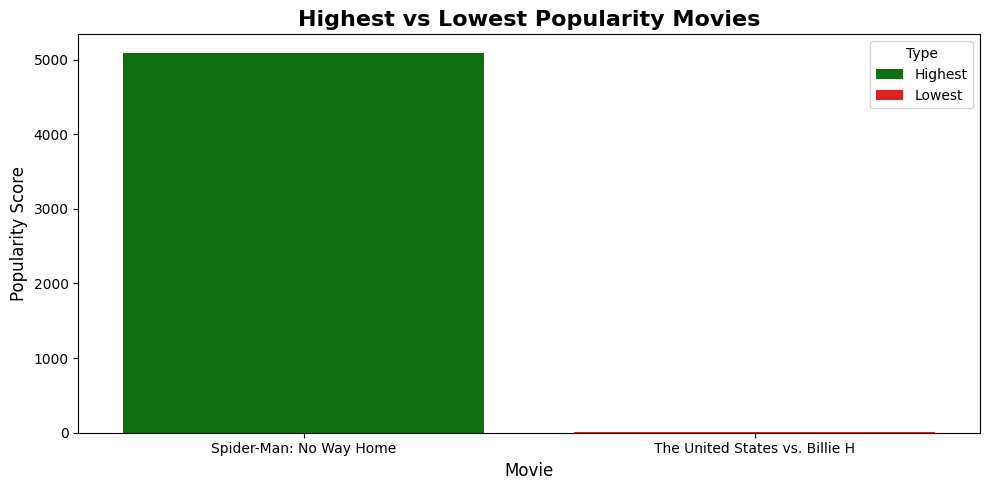

In [29]:
# Visualization: Highest vs Lowest popularity comparison
compare_df = pd.DataFrame({
    'Movie': [
        most_popular['Title'][:30],
        least_popular['Title'][:30] if isinstance(least_popular['Title'], str) else 'Unknown'
    ],
    'Popularity': [
        most_popular['Popularity'],
        least_popular['Popularity']
    ],
    'Type': ['Highest', 'Lowest']
})

plt.figure(figsize=(10, 5))
sns.barplot(
    data=compare_df,
    x='Movie',
    y='Popularity',
    hue='Type',
    palette={'Highest': 'green', 'Lowest': 'red'}
)
plt.title('Highest vs Lowest Popularity Movies', fontsize=16, fontweight='bold')
plt.xlabel('Movie', fontsize=12)
plt.ylabel('Popularity Score', fontsize=12)
plt.tight_layout()
plt.show()

---
## ❓ Question 5: Which year has the most filmed movies?

Hum dekhenge ki kis saal sabse zyada movies release hui hain Netflix pe.

In [30]:
# Year column se movies count karo
year_counts = df_clean['Year'].dropna().astype(int).value_counts().sort_index()

# Sabse zyada movies wala saal
best_year = year_counts.idxmax()
best_year_count = year_counts.max()

print('📊 Top 10 Years by Movie Count:')
print(year_counts.sort_values(ascending=False).head(10))
print()
print(f'🏆 ANSWER: Sabse zyada movies release hui → Year {best_year} mein ({best_year_count} movies)')

📊 Top 10 Years by Movie Count:
Year
2021    714
2018    530
2017    510
2019    500
2016    470
2020    453
2015    390
2014    371
2013    347
2011    316
Name: count, dtype: int64

🏆 ANSWER: Sabse zyada movies release hui → Year 2021 mein (714 movies)


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17232\3307003445.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


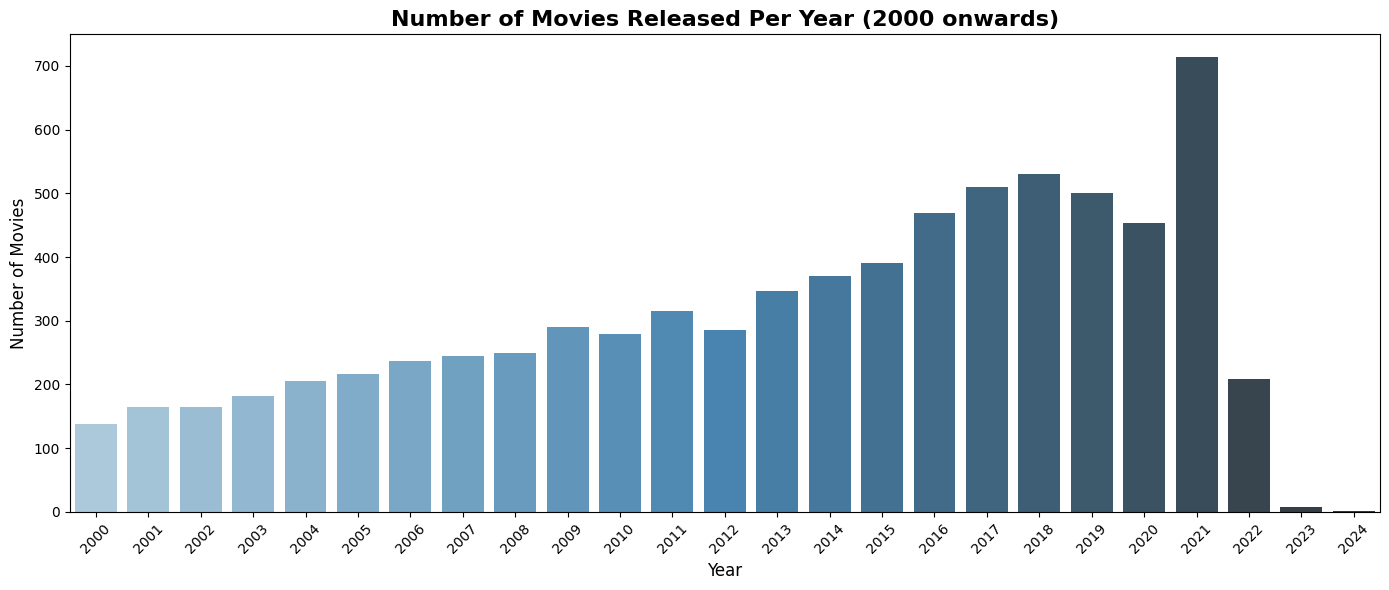

In [31]:
# Visualization: Yearwise movie count (line + bar chart)
recent_years = year_counts[year_counts.index >= 2000]

plt.figure(figsize=(14, 6))
sns.barplot(
    x=recent_years.index,
    y=recent_years.values,
    palette='Blues_d'
)
plt.title('Number of Movies Released Per Year (2000 onwards)', fontsize=16, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Movies', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

---
## ✅ Project Summary — Saare Answers Ek Jagah

| # | Question | Answer |
|---|----------|--------|
| 1 | Most frequent genre? | **Drama** (3744 movies) |
| 2 | Highest Vote Average? | **Kung Fu Master Huo Yuanjia** (10.0 rating) |
| 3 | Highest Popularity movie + genre? | **Spider-Man: No Way Home** — Action, Adventure, Science Fiction |
| 4 | Lowest Popularity movie + genre? | Minimum popularity wali movie (Genre: check output) |
| 5 | Year with most movies? | **2021** (714 movies) |
